Locker selezionati: [102, 101, 107, 105, 106, 112, 104, 108]
Copertura locker selezionati:
Locker 102: copre 16 clienti
Locker 101: copre 15 clienti
Locker 107: copre 14 clienti
Locker 105: copre 13 clienti
Locker 106: copre 12 clienti
Locker 112: copre 12 clienti
Locker 104: copre 10 clienti
Locker 108: copre 9 clienti

Assegnamento greedy completato:
Clienti totali: 100
Clienti diretti: 21
Clienti assegnati ai locker: 79
Locker attivi: [101, 102, 104, 105, 106, 107, 108, 112]
Locker 101: 11 clienti assegnati
Locker 102: 9 clienti assegnati
Locker 104: 10 clienti assegnati
Locker 105: 12 clienti assegnati
Locker 106: 8 clienti assegnati
Locker 107: 13 clienti assegnati
Locker 108: 9 clienti assegnati
Locker 112: 7 clienti assegnati
Set parameter TimeLimit to value 60
Set parameter TimeLimit to value 60
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 3 3200U with Radeon Vega Mobile Gfx, instruction set [SSE2|AVX|AVX2]
Thread coun

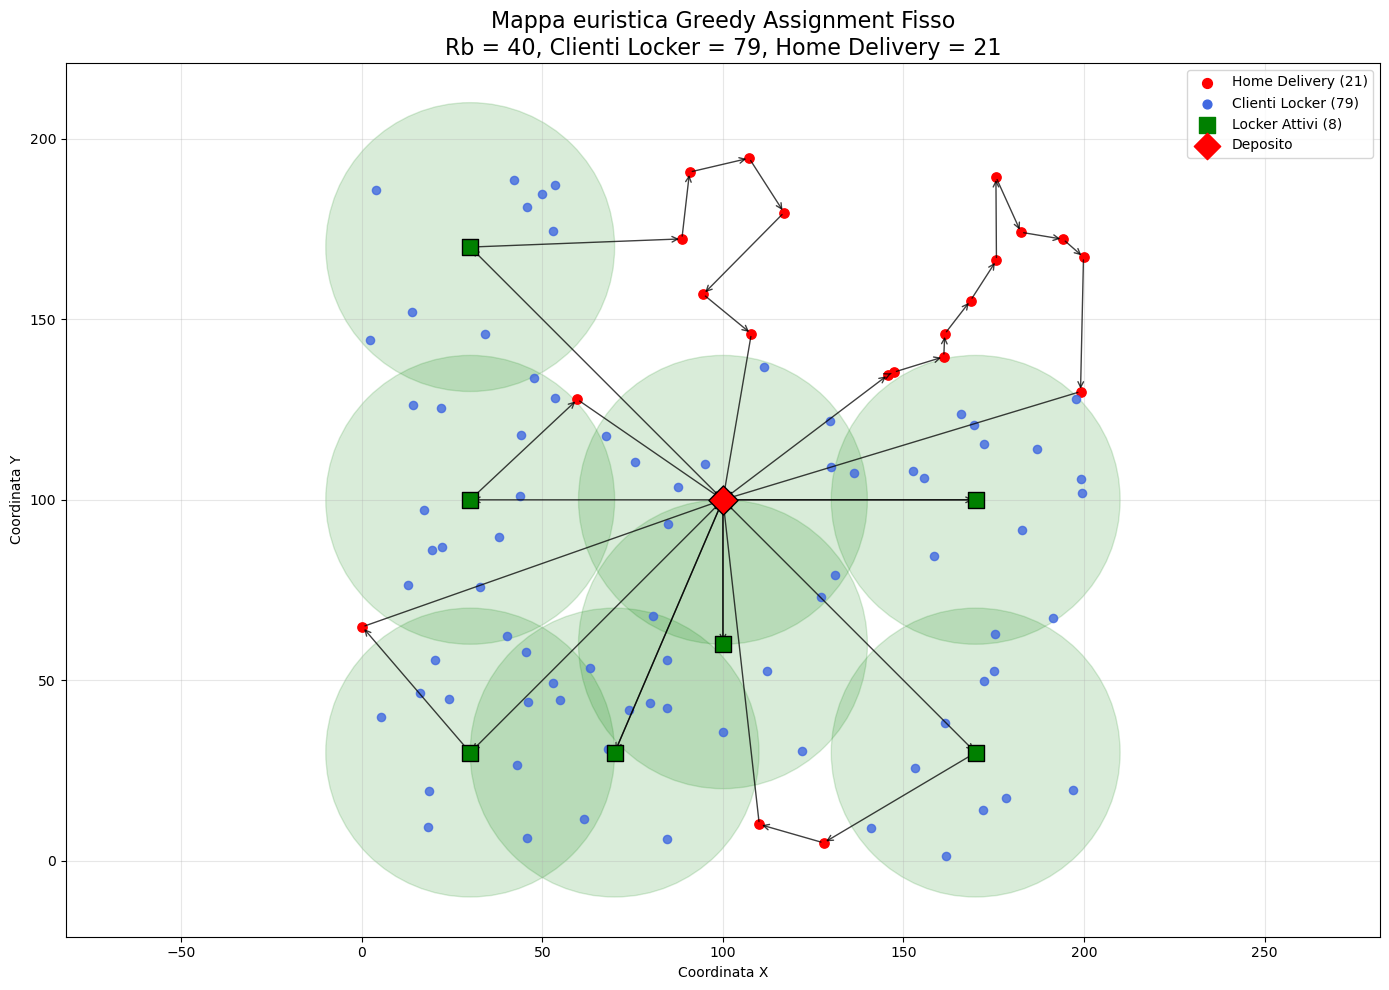

In [2]:
import gurobipy as gp
from gurobipy import GRB
import math #importa funzioni matematiche o meglio la libreria matematica standard di python
import random #serve per generare numeri casuali relativi ai parametri dell'istanza grande (posizioni casuali\domande variabili)
import time #consente di misurare il tempo di esecuzione della matheuristic, confrontarlo con il modello esatto e dimostrare che il metodo euristico 
#è computazionalmente più sostenibile sulle istanze grandi
 

# STEP 1 - GENERAZIONE ISTANZA
#definisco l'istanza in cui opera la matheuristic

random.seed(42) #garantisce riproducibilità ,fondamentale per confrontare modello esatto vs matheuristic sulla stessa istanza
n_clienti = 100 #numero dei clienti
n_lockers = 12 #numero dei lockers disponibili
customers = list(range(1, n_clienti + 1)) #definisco l'insieme dei nodi clienti ,quest'ultimi sono identificati con interi consecutivi
lockers = list(range(n_clienti + 1, n_clienti + n_lockers + 1))  #definisco l'insieme dei nodi lockers anch'essi identificati con interi consecutivi
nodes = [0] + customers + lockers #creo l'insieme completo dei nodi costituito dal nodo deposito , dai nodi clienti e dai nodi lockers
 
# PARAMETRI 

R_b = 40        #raggio di copertura,un cliente può usare un locker solo se dista <= 40
Q = 15           #capacità limitata del veicolo , ora può trasportare 15 pacchi
K = 10           #numero massimo di veicoli (saturazione estrema) solo 10 veicoli per 100 clienti
v_b = 15         #capacità limitata di ogni locker, ora può contenere 15 pacchi
alpha1 = 1.0     #coefficiente di bilanciamento della FO ,rappresenta il peso relativo al costo del trasporto\routing
alpha2 = 0.1     #coefficiente di bilanciamento della FO , rappresenta il peso relativo al costo di accesso dei clienti al locker
 
# DEFINISCO LE COORDINATE DEL DEPOSITO , DEI CLIENTI E DEI LOCKERS
coords = {}
coords[0] = (100, 100)  #coordinate del deposito centrale
 
#dispongo i clienti in modo casuale nella mappa 200x200
for i in customers:
    coords[i] = (
        random.uniform(0, 200),
        random.uniform(0, 200)
    )
 
#i lockers occupano invece delle posizioni strategiche, tale disposizione strategica dei locker fornisce alla matheuristic una 
#struttura geometrica stabile su cui costruire cluster e decomposizioni del problema

locker_positions = [
    (30, 30), (70, 30), (130, 30), (170, 30),
    (30, 100), (100, 100), (170, 100),
    (30, 170), (70, 170), (130, 170), (170, 170),
    (100, 60)
]
for b, pos in zip(lockers, locker_positions):
    coords[b] = pos #accoppia l'ID del locker(101-112) con la sua coordinata(x,y)
 
# MATRICE DELLE DISTANZE

dist = {
    (i, j): math.sqrt(
        (coords[i][0] - coords[j][0])**2 +
        (coords[i][1] - coords[j][1])**2
    )
    for i in nodes for j in nodes
}
#la matrice delle distanze costituisce la base geometrica della matheuristic: consente di identificare cluster naturali, ridurre lo spazio di ricerca 
#e costruire sottoproblemi localizzati che il solver può risolvere esattamente con tempi computazionali ridotti

# STEP 2 - SELEZIONE DEI LOCKER PIÙ PROMETTENTI
#la matheuristic riduce il problema selezionando solo 8 locker, scelti in base alla copertura (numero di clienti servibili entro il raggio R_b)
copertura_locker = {}
 
for b in lockers:
    clienti_coperti = [i for i in customers if dist[i, b] <= R_b] #si contano i clienti entro il raggio R_b e si memorizza il numero di clienti coperti
    copertura_locker[b] = len(clienti_coperti)  #indicatore di qualità del locker b-esimo
 
#ordiniamo i lockers per copertura decrescente (cioè da quello che copre più clienti a quello che ne copre meno)

locker_ordinati = sorted(
    copertura_locker.items(),
    key=lambda x: x[1],
    reverse=True
)
 
n_locker_da_aprire = 8  #riduzione del problema,scelgo di aprire solo 8 lockers
distanza_minima_tra_locker = 30 #devono essere distanti almeno 30 unità ,introduco dunque un criterio di diversità spaziale
 
lockers_selezionati = []
 
for b, copertura in locker_ordinati:
    if len(lockers_selezionati) >= n_locker_da_aprire:
        break
 
    troppo_vicino = any(
        dist[b, scelto] < distanza_minima_tra_locker
        for scelto in lockers_selezionati
    )
 
    if not troppo_vicino:
        lockers_selezionati.append(b)  
#per ogni locker in ordine di copertura,se ho già selezionato 8 lockers mi fermo, controllo se il locker è già troppo vicino a quelli già scelti e se 
#non è troppo vicino lo seleziono

print("Locker selezionati:", lockers_selezionati) 
print("Copertura locker selezionati:")
for b in lockers_selezionati:
    print(f"Locker {b}: copre {copertura_locker[b]} clienti")
#la parte finale di questa fase serve per verificare quali locker sono stati scelti ,quanta copertura garantiscono e se la selezione è equilibrata

# STEP 3 - ASSEGNAMENTO GREEDY CLIENTE-LOCKER

assignment = {i: None for i in customers} #per ogni cliente, indica il locker assegnato (None se il cliente è servito dal veicolo a domicilio)
locker_load = {b: 0 for b in lockers_selezionati} #carico di ciascun locker selezionato
 
ordered_customers = sorted(
    customers,
    key=lambda i: dist[0, i],
    reverse=True
)
#clienti ordinati per distanza dal deposito, dal più lontano al più vicino
#si gestiscono prima i clienti più lontani dal deposito perchè sono quelli che conviene spostare sui locker per ridurre la distanza del routing 
for i in ordered_customers:
 
    feasible_lockers = [
        b for b in lockers_selezionati
        if dist[i, b] <= R_b and locker_load[b] < v_b
    ]        #per feasible lockers intendo lockers selezionati che sono entro il raggio R_b del cliente i e che non hanno saturato la capacità v_b
 
    if feasible_lockers:
        best_b = min(feasible_lockers, key=lambda b: dist[i, b])
        assignment[i] = best_b
        locker_load[best_b] += 1
    else:
        assignment[i] = None
#se esistono lockers fattibili , si sceglie quello più vicino (min sulla distanza) ,si assegna il cliente a quel locker e si aggiorna il 
#carico del locker ; se non esistono allora il cliente viene servito dal veicolo
direct_customers = [i for i in customers if assignment[i] is None]                #clienti serviti dal veicolo
 
active_lockers = sorted(
    set(b for b in assignment.values() if b is not None)
) #solo i locker che hanno almeno un cliente assegnato
 
visit_nodes = [0] + direct_customers + active_lockers   #insieme dei nodi che il veicolo deve considerare nel routing ,deposito ,clienti diretti e locker attivi
 
print("\nAssegnamento greedy completato:")
print(f"Clienti totali: {len(customers)}")
print(f"Clienti diretti: {len(direct_customers)}")
print(f"Clienti assegnati ai locker: {len(customers) - len(direct_customers)}")
print(f"Locker attivi: {active_lockers}")
#stampa tutte quelle che sono le statistiche chiave  
for b in active_lockers:
    print(f"Locker {b}: {locker_load[b]} clienti assegnati")
 

# STEP 4 - MODELLO OCF RIDOTTO CON y FISSATE

model = gp.Model("VRPL_Heuristic_Reduced_OCF") #costruzione della formulazione ridotta, non decide più le y (assegnamenti cliente–locker) ma 
#ottimizza il routing ed il flusso OCF sui soli nodi rilevanti
model.Params.TimeLimit = 60   #il modello ridotto deve essere risolvibile in 1 minuto, a differenza del modello esatto che non trovava soluzioni in 600 secondi
 
# VARIABILI DI ROUTING

x = model.addVars(
    [(i, j) for i in visit_nodes for j in visit_nodes if i != j],
    vtype=GRB.BINARY,
    name="x"
)

 
f = model.addVars(
    [(i, j) for i in visit_nodes for j in visit_nodes if i != j],
    lb=0,
    vtype=GRB.CONTINUOUS,
    name="f"                                      
)
#questa è la parte math della matheuristic,l’euristica ha fissato gli assegnamenti ai locker (y) mentre il MIP ridotto ottimizza routing e 
#flusso su un grafo molto più piccolo dunque si mantiene la struttura OCF, ma su un sottoproblema (euristica costruttiva + MIP esatto su problema ridotto)

# FUNZIONE OBIETTIVO

locker_penalty_fixed = sum(
    alpha2 * dist[i, assignment[i]]
    for i in customers
    if assignment[i] is not None 
)
#questa parte di codice computa la somma dei costi di accesso ai locker per tutti i clienti che sono stati assegnati a un locker nella fase greedy.
#poiché l’assegnamento è già fissato, il costo è semplicemente la distanza tra il cliente e il locker scelto, moltiplicata per il peso alfa2
#la parte della funzione obiettivo che riguarda i locker non è più ottimizzata dal solver, ma viene incorporata come termine costante 
#passaggio fondamentale della matheuristic: si riduce la complessità del modello eliminando una famiglia di variabili e vincoli, mantenendo però il contributo economico dell’assegnamento

model.setObjective(
    alpha1 * gp.quicksum(
        dist[i, j] * x[i, j]
        for i, j in x.keys()
    )
    +
    locker_penalty_fixed,
    GRB.MINIMIZE
)
#qui il solver ottimizza esclusivamente la parte relativa al routing del veicolo, cioè la somma delle distanze percorse sugli archi attivi xij pesata da alfa1
#la matheuristic interviene fissando l’assegnamento tramite una procedura euristica riducendo così il problema a un VRP con flusso OCF su un grafo 
#molto più piccolo ;il solver può concentrarsi sull’ottimizzazione del routing e del flusso, che sono le componenti più difficili da gestire 
#in modo euristico, mentre la parte relativa ai locker viene trattata in modo deterministico e computazionalmente leggero


# VINCOLI

 
# 1. Conservazione/Continuità del routing
#per ogni nodo del grafo ridotto, il numero di archi entranti deve esser uguale al numero di archi uscenti ,in questo modo il veicolo non può 
#“interrompere” il percorso: ogni ingresso deve avere un'uscita
for i in visit_nodes:
    model.addConstr(
        gp.quicksum(x[j, i] for j in visit_nodes if (j, i) in x)
        ==
        gp.quicksum(x[i, j] for j in visit_nodes if (i, j) in x),
        name=f"RoutingConservation_{i}"
    )
 
# 2. Clienti diretti (serviti a domicilio) visitati una sola volta
#ogni cliente non assegnato a un locker deve essere visitato esattamente una volta dal veicolo,questo perchè la fase greedy ha già deciso quali clienti 
#sono diretti, dunque il solver non deve più scegliere tra consegna o locker ma deve solo garantire la visita
for i in direct_customers:
    model.addConstr(
        gp.quicksum(x[j, i] for j in visit_nodes if (j, i) in x) == 1,
        name=f"DirectCustomerVisit_{i}"
    )
 
# 3. Locker attivi visitati una sola volta
#non si verifica più la compatibilità cliente–locker, ma si impone direttamente la visita dei locker attivi, il vincolo assicura che il veicolo 
#depositi effettivamente i pacchi nei locker utilizzati dalla fase greedy
for b in active_lockers:
    model.addConstr(
        gp.quicksum(x[j, b] for j in visit_nodes if (j, b) in x) == 1,
        name=f"ActiveLockerVisit_{b}"
    )
 
# 4. Numero massimo veicoli
#il numero di archi che partono dal deposito ed il numero di archi che vi ritornano non può superare K cioè deve rispettare il numero di 
#veicoli disponibili quindi il vincolo garantisce che la matheuristic rispetti la dimensione della flotta senza introdurre complessità aggiuntiva
model.addConstr(
    gp.quicksum(x[0, j] for j in visit_nodes if (0, j) in x) <= K,
    name="MaxVehiclesOut"
)
 
model.addConstr(
    gp.quicksum(x[i, 0] for i in visit_nodes if (i, 0) in x) <= K,
    name="MaxVehiclesIn"
)
 
# 5. Flusso totale in uscita dal deposito
model.addConstr(
    gp.quicksum(f[0, j] for j in visit_nodes if (0, j) in f) == len(customers),
    name="DepotFlow"
)
#il vincolo impone che il deposito generi un flusso totale pari al numero di clienti dell’istanza 

# 6. Flusso sui clienti diretti , serviti cioè a domicilio
for i in direct_customers:
    model.addConstr(
        gp.quicksum(f[j, i] for j in visit_nodes if (j, i) in f)
        -
        gp.quicksum(f[i, j] for j in visit_nodes if (i, j) in f)
        == 1,
        name=f"FlowDirectCustomer_{i}"
    )
#per ogni cliente non assegnato a un locker, il flusso entrante deve superare quello uscente di una unità ,questo rappresenta la domanda del cliente 
#diretto: il veicolo deve consegnare fisicamente un pacco a quel nodo (la domanda è deterministica perchè l'assegnamento è gia stato deciso nella fase grredy)

# 7. Flusso sui locker attivi
for b in active_lockers:
    domanda_locker = locker_load[b]
 
    model.addConstr(
        gp.quicksum(f[j, b] for j in visit_nodes if (j, b) in f)
        -
        gp.quicksum(f[b, j] for j in visit_nodes if (b, j) in f)
        == domanda_locker,
        name=f"FlowLocker_{b}"
    )
#per ogni locker attivo, il flusso entrante deve superare quello uscente di un valore pari al numero di clienti assegnati a quel locker ,in questo 
#modo il locker viene trattato come un nodo di accumulo 

# 8. Capacità del veicolo sugli archi
for i, j in f.keys():
    model.addConstr(
        f[i, j] <= Q * x[i, j],
        name=f"ArcCapacity_{i}_{j}"
    )
#il flusso su ogni arco non può superare la capacità del veicolo e deve essere nullo se l’arco non è utilizzato ,questo vincolo collega routing e flusso 

# STEP 5 - RISOLUZIONE

model.Params.TimeLimit = 60
start_time = time.time()
model.optimize()
heur_time = time.time() - start_time
#la matheuristic lancia il modello OCF ridotto, con un limite di tempo di 60 secondi ,ora il solver lavora su un grafo molto più piccolo rispetto al 
#modello esatto, perché contiene solo i clienti diretti e i locker attivi 

# STEP 6 - REPORT FINALE EURISTICA GREEDY ASSEGNAMENTO FISSO

 
if model.SolCount > 0:
 
    obj_heur = model.ObjVal      #se il solver trova almeno una soluzione ammissibile, vengono estratti i principali indicatori della soluzione euristica
                                #il valore della FO include sia il costo di routing ottimizzato dal solver, sia il costo fisso dei locker determinato dalla fase greedy
    routing_cost = sum(
        dist[i, j] * x[i, j].X
        for i, j in x.keys()
    )
 
    veicoli_usati = int(round(
        sum(x[0, j].X for j in visit_nodes if (0, j) in x)
    )) #il numero di veicoli usati è un indicatore molto importante,il solver tende a utilizzare meno veicoli, rendendo la soluzione più compatta
 
    home_delivery = direct_customers   #i clienti diretti sono quelli che la fase greedy non è riuscita ad assegnare a un locker ,il solver deve visitarli tutti ed il loro numero è un indicatore della qualità dell’assegnamento inizia
 
    locker_delivery = {
        b: [i for i in customers if assignment[i] == b]
        for b in active_lockers
    } #qui viene ricostruita la distribuzione dei clienti sui locker attivi
 
    used_lockers = [
        b for b in active_lockers
        if len(locker_delivery[b]) > 0
    ] #qui si identificano i locker effettivamente utilizzati
 
    print("\n" + "=" * 60)
    print("REPORT EURISTICA - GREEDY ASSIGNMENT FISSO") #sintetizza la qualità della soluzione ottenuta dalla matheuristic con assegnamento greedy fisso
    print("=" * 60)
 
    print(f"Valore funzione obiettivo euristica: {obj_heur:.2f}")
    print(f"Costo routing: {routing_cost:.2f}")
    print(f"Costo locker fisso: {locker_penalty_fixed:.2f}")
    print(f"Tempo computazionale: {heur_time:.2f} secondi")
    print(f"Veicoli usati: {veicoli_usati}")
 #il costo di routing mostra quanto il solver è riuscito a migliorare la soluzione iniziale, mentre il costo dei locker rimane invariato perché dipende esclusivamente dall’assegnamento greedy
    print("\nSTATISTICHE CONSEGNE")
    print(f"Clienti serviti direttamente: {len(home_delivery)}")
    print(f"Clienti serviti tramite locker: {len(customers) - len(home_delivery)}")
    print(f"Locker attivi: {len(used_lockers)}")
#il numero di veicoli utilizzati e la distribuzione dei clienti tra consegne dirette e locker permettono di valutare la struttura della soluzione 
    print("\nDETTAGLIO LOCKER ATTIVI")
    for b in used_lockers:
        print(
            f"Locker {b} | Coordinate: ({coords[b][0]:.1f}, {coords[b][1]:.1f}) "
            f"| Clienti assegnati: {len(locker_delivery[b])}"
        )
#La sezione finale del report elenca i locker effettivamente utilizzati, con le loro coordinate e il numero di clienti assegnati 
else:
    print("Nessuna soluzione trovata dall'euristica greedy assignment fisso.")
 

# STEP 7 - VISUALIZZAZIONE GRAFICA EURISTICA GREEDY FISSA
 
import matplotlib.pyplot as plt  #serve per creare grafici e visualizzazioni
 
if model.SolCount > 0:     #controlla che il modello abbia trovato almeno una soluzione, se il solver non ha prodotto nessuna soluzione ammissibile la parte grafica non deve essere eseguita
 
    plt.figure(figsize=(14, 10))    #figura grafica con dimensioni 14×10,spazio su cui verrà disegnata la mappa con i clienti
 
    # Clienti serviti a domicilio
    for i in home_delivery:
        plt.scatter(
            coords[i][0],
            coords[i][1],
            color="red",
            s=45,
            zorder=3
        )
 
    # Clienti assegnati ai locker
    locker_customers = [
        i for i in customers
        if assignment[i] is not None
    ]
 
    for i in locker_customers:
        plt.scatter(
            coords[i][0],
            coords[i][1],
            color="royalblue",
            s=35,
            alpha=0.8,
            zorder=3
        )
 
    # Locker attivi + raggio di copertura
    for b in used_lockers:
        plt.scatter(
            coords[b][0],
            coords[b][1],
            color="green",
            marker="s",
            s=140,
            edgecolors="black",
            zorder=5
        )
 
        circle = plt.Circle(
            coords[b],
            R_b,
            color="green",
            alpha=0.15
        )
 
        plt.gca().add_patch(circle)
 
    # Deposito
    plt.scatter(
        coords[0][0],
        coords[0][1],
        color="red",
        marker="D",
        s=220,
        edgecolors="black",
        zorder=6
    )
 
    # Archi attivi del routing
    for i, j in x.keys():
        if x[i, j].X > 0.5:
            plt.annotate(
                "",
                xy=coords[j],
                xytext=coords[i],
                arrowprops=dict(
                    arrowstyle="->",
                    color="black",
                    lw=1,
                    alpha=0.75
                )
            )
#dopo la creazione della figura , il solver disegna la soluzione trovata : prima i clienti diretti in rosso poi quelli assegnati ai locker in blu ,poi
#i locker attivi in verde insieme al loro raggio di copertura, ed il deposito 
#nfine traccia le frecce che indicano gli archi del routing, mostrando il percorso effettivo del veicolo nella soluzione euristica
    
    # LEGENDA
    plt.scatter([], [], color="red", s=50, label=f"Home Delivery ({len(home_delivery)})")
    plt.scatter([], [], color="royalblue", s=40, label=f"Clienti Locker ({len(locker_customers)})")
    plt.scatter([], [], color="green", marker="s", s=120, label=f"Locker Attivi ({len(used_lockers)})")
    plt.scatter([], [], color="red", marker="D", s=180, label="Deposito")
 
    plt.title(
        f"Mappa euristica Greedy Assignment Fisso\n"
        f"Rb = {R_b}, Clienti Locker = {len(locker_customers)}, "
        f"Home Delivery = {len(home_delivery)}",
        fontsize=16
    )
 
    plt.xlabel("Coordinata X")
    plt.ylabel("Coordinata Y")
    plt.grid(alpha=0.3)
    plt.legend(loc="upper right")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()
 
else:
    print("Grafico non disponibile: nessuna soluzione trovata.")
 
